# DOGMA-seq: chromatin, RNA and protein from one cell

This notebook tells the story of fitting the **Chromatin** model with a protein layer to a
real tri-modal dataset: the DIG control of Mimitou et al. (2021), DOGMA-seq on human PBMCs
(GEO [GSE156478](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE156478)). Each cell
carries three assays: a cellranger-arc GEX + ATAC library and a 210-antibody TotalSeq-A panel
(ADT). One cell type, CD4 T cells, and the 28 genes whose antibody is on the panel and whose
locus has two ATAC sites within 5 kb of the transcription start.

The model: a locus of two binary chromatin sites opens and closes (an Ising chain), the open
configuration sets the nascent transcription rate (`switch` rule), the RNA splices and degrades,
and the mature RNA is translated into a protein that degrades. Four observed modalities per cell:
nascent RNA, mature RNA, protein counts, and the configuration read out by ATAC.

| Symbol | Meaning |
|---|---|
| $k_{on,0}, k_{on,1}$ | opening rate of each site, in units of the closing rate |
| $\epsilon$ | neighbour coupling between the sites |
| $a$ | nascent transcription rate when the locus is open |
| $\beta$, $\gamma$ | splicing and mature-RNA degradation rates |
| $b$ | burst size (bursty emission) |
| $k_p$, $\gamma_p$ | protein production and degradation rates |

The sampling vector holds the RNA capture (Poisson, per channel), the ATAC dropout and the
per-antibody protein background. The design record is `docs/chromatin-protein-design.md`;
this notebook merges the scripts that produced it and runs the final versions.

**What the notebook does, in order**

1. Assembles the three assays onto called cells and builds the four-layer AnnData.
2. Measures the protein background and removes antibody aggregates and mislabelled cells.
3. Removes the multi-antibody droplet class and measures a per-cell factor.
4. Fits the joint model, with and without the per-cell factor.
5. Reads the fit against the sampling floor of the goodness-of-fit statistic.
6. Shows why the abundant antibodies are rejected: heavy protein tails.
7. Splits by cell state (activated versus resting CD4 T cells).
8. Checks the burst size of every gene against an RNA-only refit.

A pass over the 28 genes takes about 45 minutes on a 24-core server (four hours before the batched
stencil and then the adjoint gradient; see the cost study in the design doc), so by default the notebook loads the saved results from
`fits/` under the data directory; set `DOGMA_RUN_FITS=1` to rerun them. The data directory is
`DOGMA_DATA` (default `~/geo/GSE156478`), laid out as the assembly cells write it. The raw GEO
and kb files are only needed to rebuild the assembled h5ads.

In [1]:
# Work from the repository root (figures in figures/) and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))

In [2]:
import time, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import matplotlib.pyplot as plt

from monod.cme_toolbox import CMEModel, _HAS_RUST
from monod.extract_data import tail_droplets, write_h5ad
from monod.inference import (perform_inference, rna_only_check, search_result_from_uns, searchdata_from_adata,
                             warm_start, hellinger_statistic, hellinger_floor)

warnings.filterwarnings('ignore')
os.makedirs('figures', exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 60)

DATA = os.path.expanduser(os.environ.get('DOGMA_DATA', '~/geo/GSE156478'))
FITS = f'{DATA}/fits'
RUN_FITS = os.environ.get('DOGMA_RUN_FITS', '0') == '1'
STEM = f'{DATA}/mimitou_CD4_T_tss_window_2_protein'           # the assembled CD4 T AnnData and its filtered versions
if not os.path.isdir(DATA):
    raise FileNotFoundError(f'{DATA}: set DOGMA_DATA to the directory holding the assembled GSE156478 files')
print(f'Rust backend: {_HAS_RUST}; data: {DATA}; rerun fits: {RUN_FITS}')

# chart chrome: thin marks, recessive axes, a fixed categorical order
C = {'blue': '#2a78d6', 'orange': '#eb6834', 'aqua': '#1baf7a', 'yellow': '#eda100', 'muted': '#898781', 'grid': '#e1e0d9', 'ink': '#52514e'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': C['muted'],
                     'axes.labelcolor': C['ink'], 'xtick.color': C['ink'], 'ytick.color': C['ink'],
                     'axes.grid': True, 'grid.color': C['grid'], 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'figure.dpi': 110, 'font.size': 9})
def to_dense(x):
    return np.asarray(x.toarray() if sp.issparse(x) else x, dtype=float)

Rust backend: True; data: /home/coakes/geo/GSE156478; rerun fits: False


---
## 1 · Three assays onto one cell

Stage 1 reads the cellranger-arc filtered matrix and splits it into gene expression and peaks,
puts the raw ADT counts onto the called barcodes, and labels coarse cell types from GEX clusters
and the marker antibodies (CD3, CD4, CD8a, CD14, CD19, CD20, CD56, CD123). Stage 2 replaces the
arc GEX counts with a `kb-python` `nac` quantification of the same reads, so that nascent and
mature RNA are separate layers (unspliced = nascent, spliced = mature + ambiguous), takes one
cell type, and calls `chromatin_data.build_multiome_adata` with the ADT matrix as the protein
layer and a gene-to-antibody map.

The functions below are the two stages as scripts; they run only when their outputs are missing.

In [3]:
def assemble_stage1(base):
    '''cellranger-arc filtered matrix -> atac.h5ad, arc_gex.h5ad; ADT counts on the called cells -> protein.h5ad;
    coarse cell types from GEX Leiden clusters and marker antibodies -> cells.csv.'''
    import scipy.io, scanpy as sc
    geo = f'{base}/geo'
    bc = pd.read_csv(f'{geo}/GSM5065531_DIG_CTRL_GExp_ATAC_filtered_barcodes.tsv.gz', header=None)[0].tolist()
    feat = pd.read_csv(f'{geo}/GSM5065531_DIG_CTRL_GExp_ATAC_filtered_features.tsv.gz', sep='\t', header=None,
                       names=['id', 'name', 'kind', 'chrom', 'start', 'end'])
    M = scipy.io.mmread(f'{geo}/GSM5065531_DIG_CTRL_GExp_ATAC_filtered_matrix.mtx.gz').tocsr()          # features x cells
    is_gex = (feat.kind == 'Gene Expression').values
    gex = ad.AnnData(X=M[is_gex].T.tocsr().astype(np.float32), obs=pd.DataFrame(index=bc),
                     var=feat[is_gex].set_index('name')[['id', 'chrom', 'start', 'end']])
    gex.var_names_make_unique()
    pk = feat[~is_gex]
    atac = ad.AnnData(X=M[~is_gex].T.tocsr().astype(np.float32), obs=pd.DataFrame(index=bc),
                      var=pd.DataFrame({'chrom': pk.chrom.values, 'start': pk.start.values.astype(int), 'end': pk.end.values.astype(int)},
                                       index=[f'{c}:{int(s)}-{int(e)}' for c, s, e in zip(pk.chrom, pk.start, pk.end)]))
    # ADT: raw barcodes (without the -1 suffix) x 210 proteins
    adt_bc = pd.read_csv(f'{geo}/GSM5065532_DIG_ctrl_ADT_allCounts.barcodes.txt.gz', header=None)[0].tolist()
    prot = pd.read_csv(f'{geo}/GSM5065532_DIG_ctrl_ADT_allCounts.proteins.txt.gz', header=None)[0].tolist()
    A = scipy.io.mmread(f'{geo}/GSM5065532_DIG_ctrl_ADT_allCounts.mtx.gz').tocsr()
    if A.shape[0] == len(prot):
        A = A.T.tocsr()
    pos = {b: i for i, b in enumerate(adt_bc)}
    rows = [pos.get(b[:-2], -1) for b in bc]
    Acells = sp.vstack([A[r] if r >= 0 else sp.csr_matrix((1, A.shape[1])) for r in rows]).tocsr()
    protein = ad.AnnData(X=Acells.astype(np.float32), obs=pd.DataFrame(index=bc), var=pd.DataFrame(index=prot))
    tot = np.asarray(protein.X.sum(1)).ravel()
    # coarse cell types: Leiden on GEX, labels from the cluster medians of the marker antibodies
    g = gex.copy()
    sc.pp.filter_genes(g, min_cells=10); sc.pp.normalize_total(g, target_sum=1e4); sc.pp.log1p(g)
    sc.pp.highly_variable_genes(g, n_top_genes=2000); sc.pp.pca(g, n_comps=30, mask_var='highly_variable')
    sc.pp.neighbors(g, n_neighbors=15); sc.tl.leiden(g, resolution=0.5, flavor='igraph', n_iterations=2, key_added='cluster')
    markers = ['CD3-1', 'CD4-1', 'CD8a', 'CD14', 'CD16', 'CD19', 'CD20', 'CD56(NCAM)', 'HLA-DR', 'CD11c', 'CD123', 'CD34', 'CD45-1']
    clr = np.log1p(protein[:, markers].X.toarray() / np.maximum(tot[:, None], 1) * 1e3)
    df = pd.DataFrame(clr, columns=markers, index=bc); df['cluster'] = g.obs['cluster'].values
    med = df.groupby('cluster').median(); t_level = med['CD3-1'].quantile(0.25)
    def label(row):
        if row['CD14'] > med['CD14'].median() + 1.0 and row['CD3-1'] < t_level: return 'CD14 Mono'
        if row['CD123'] > med['CD123'].median() + 1.5 and row['CD3-1'] < t_level: return 'pDC'
        if row['CD19'] > med['CD19'].median() + 1.0 or row['CD20'] > med['CD20'].median() + 1.0: return 'B'
        if row['CD56(NCAM)'] > med['CD56(NCAM)'].median() + 0.8 and row['CD3-1'] < t_level: return 'NK'
        if row['CD3-1'] >= t_level and row['CD8a'] > row['CD4-1']: return 'CD8 T'
        if row['CD3-1'] >= t_level: return 'CD4 T'
        return 'other'
    g.obs['cell_type'] = g.obs['cluster'].map({c: label(r) for c, r in med.iterrows()})
    cells = pd.DataFrame({'cluster': g.obs['cluster'].values, 'cell_type': g.obs['cell_type'].values, 'adt_total': tot,
                          'gex_umis': np.asarray(gex.X.sum(1)).ravel(), 'peak_fragments': np.asarray(atac.X.sum(1)).ravel()}, index=bc)
    cells.to_csv(f'{base}/cells.csv')
    for a_, name in ((atac, 'atac'), (protein, 'protein'), (gex, 'arc_gex')):
        a_.obs = a_.obs.join(cells); a_.write_h5ad(f'{base}/{name}.h5ad')


def assemble_stage2(base, protein_map, cell_type='CD4 T', rule='tss_window', n_sites=2, window=5000,
                    gtf='~/geo/ref/gencode.v32.primary_assembly.annotation.gtf.gz'):
    '''kb nac counts on the called cells -> rna_nac.h5ad; one cell type through build_multiome_adata with the
    ADT counts as the protein layer -> mimitou_<type>_<rule>_<n_sites>_protein.h5ad and a gene table.'''
    import scipy.io
    from monod import chromatin_data as cd
    rna_path = f'{base}/rna_nac.h5ad'
    if not os.path.exists(rna_path):
        kb = f'{base}/kb/counts_unfiltered'
        barcodes = [l.strip() for l in open(f'{kb}/cells_x_genes.barcodes.txt')]
        ids = [l.strip().split('.')[0] for l in open(f'{kb}/cells_x_genes.genes.txt')]
        names = [l.strip() for l in open(f'{kb}/cells_x_genes.genes.names.txt')]
        cells = pd.read_csv(f'{base}/cells.csv', index_col=0)
        pos = {b: i for i, b in enumerate(barcodes)}
        keep = [c for c in cells.index if c[:-2] in pos]; rows = [pos[c[:-2]] for c in keep]
        parts = {k: scipy.io.mmread(f'{kb}/cells_x_genes.{k}.mtx').tocsr()[rows] for k in ('nascent', 'mature', 'ambiguous')}
        unspliced = parts['nascent']; spliced = (parts['mature'] + parts['ambiguous']).tocsr()
        rna = ad.AnnData(X=spliced.copy(), obs=cells.loc[keep], var=pd.DataFrame({'gene_id': ids}, index=names),
                         layers=dict(unspliced=unspliced, spliced=spliced, ambiguous=parts['ambiguous'].tocsr()))
        rna.var_names_make_unique(); rna.write_h5ad(rna_path)
    rna = ad.read_h5ad(rna_path); atac = ad.read_h5ad(f'{base}/atac.h5ad'); protein = ad.read_h5ad(f'{base}/protein.h5ad')
    rna_c = rna[(rna.obs['cell_type'] == cell_type).values].copy()
    genes = cd.genes_table(os.path.expanduser(gtf))
    out = cd.build_multiome_adata(rna_c, atac, genes, rule=rule, n_sites=n_sites, threshold=1, layers=('unspliced', 'spliced'),
                                  min_open_fraction=0.02, protein=protein, protein_map=protein_map, window=window)
    tag = cell_type.replace('+', '').replace(' ', '_')
    out.write_h5ad(f'{base}/mimitou_{tag}_{rule}_{n_sites}_protein.h5ad')
    return out

In [4]:
if not os.path.exists(f'{DATA}/cells.csv'):
    assemble_stage1(DATA)
if not os.path.exists(STEM + '.h5ad'):
    sys.path.insert(0, os.path.expanduser('~'))
    from mimitou_protein_map import PROTEIN_MAP          # gene symbol -> antibody name for the TotalSeq-A panel
    assemble_stage2(DATA, PROTEIN_MAP)

cells = pd.read_csv(f'{DATA}/cells.csv', index_col=0)
print(f'{len(cells)} called cells; ADT total per cell: median {cells.adt_total.median():.0f}; GEX UMIs: median {cells.gex_umis.median():.0f}')
print(cells.cell_type.value_counts().to_frame('cells').T.to_string())

raw = ad.read_h5ad(STEM + '.h5ad')
print(f'\nCD4 T: {raw.n_obs} cells x {raw.n_vars} genes with an antibody and a two-site locus; layers {list(raw.layers)}')
dense = {k: to_dense(raw.layers[k]) for k in ('unspliced', 'spliced', 'protein')}
genes_tab = pd.DataFrame({'antibody': raw.var['antibody'].values,
                          'nascent mean': dense['unspliced'].mean(0).round(3), 'mature mean': dense['spliced'].mean(0).round(2),
                          'protein mean': dense['protein'].mean(0).round(1), 'protein Fano': (dense['protein'].var(0) / dense['protein'].mean(0)).round(1),
                          'protein max': dense['protein'].max(0).astype(int)}, index=raw.var_names)
cfg = np.asarray(raw.layers['configuration'])
genes_tab['open frac (site 0, 1)'] = [f'{a:.2f}, {b:.2f}' for a, b in zip(((cfg & 1) > 0).mean(0), ((cfg & 2) > 0).mean(0))]
genes_tab.sort_values('protein mean', ascending=False)

11868 called cells; ADT total per cell: median 2302; GEX UMIs: median 2090
cell_type  CD4 T  CD8 T    B  other  pDC
cells       8526   2248  586    320  188

CD4 T: 8526 cells x 28 genes with an antibody and a two-site locus; layers ['configuration', 'protein', 'spliced', 'unspliced']


,antibody,nascent mean,mature mean,protein mean,protein Fano,protein max,"open frac (site 0, 1)"
CD4,CD4-1,0.100,0.06,824.1,297.0,4270,"0.04, 0.05"
CD27,CD27,0.001,0.09,71.3,44.1,3246,"0.07, 0.02"
ITGB7,integrin_7,0.026,0.05,29.2,63.1,624,"0.04, 0.09"
ITGA4,CD49d,1.052,0.22,24.0,36.5,363,"0.23, 0.04"
ICOS,CD278,0.303,0.06,19.0,37.7,1077,"0.06, 0.09"
IL2RA,CD25,0.390,0.12,9.3,63.7,667,"0.12, 0.04"
CD52,CD52,0.022,0.47,6.7,12.6,570,"0.03, 0.10"
NOTCH1,Notch1,0.051,0.09,6.2,3.9,148,"0.03, 0.35"
CD63,CD63,0.005,0.13,5.5,31.2,406,"0.17, 0.03"
FAS,CD95,0.025,0.15,4.8,12.8,282,"0.02, 0.20"


Two things stand out before any fit. The protein counts span four orders of mangitude across antibodies
(CD4 near a thousand counts per cell, PD-1 or CD79a at one or two), and the Fano factors of the
abundant antibodies are in the hundreds. The low antibodies are targets that CD4 T cells do not
express; their counts are **background**, nonspecific binding that every antibody carries. The
spread of the abundant ones is the question the rest of the notebook works through.

---
## 2 · The protein channel: background, aggregates, mislabelled cells

**Background.** The level is antibody-specific and does not follow the ambient pool's composition
(an ambient model scaled to a cell's total would put 0.3 CD79a counts on a cell, not 1.9), so it
is estimated per antibody: the mean count on the least-expressing cell type with at least 150
cells, aggregates removed within the type. Where no type is negative (pan-leukocyte targets such
as CD45 and CD52) the panel floor of one count is used. The model takes it as a fixed per-gene
rate in `var['log10_protein_background']`, held by `protein_background=(0, 0, 1)`.

**Aggregates.** A few cells carry hundreds of counts of one antibody, far above its bulk; they set
the protein grid limit and the coarse protein axis then loses the bulk of the distribution. A
cell with any antibody above three times its 99th percentile is dropped (qc).

**Mislabelled cells.** A fifth of the "CD4 T" cluster is CD4-low and CD8a-high (CD8 T cells and
a few NK cells carried along by the cluster). Cells with CD4 ≥ 250 and CD8a < 250 ADT counts
are kept (qc2).

In [5]:
prot = ad.read_h5ad(f'{DATA}/protein.h5ad')
P210 = pd.DataFrame(to_dense(prot.X), index=prot.obs_names, columns=prot.var_names).loc[cells.index]
ab = raw.var['antibody']

def background_table(P210, cells, ab, min_cells=150):
    '''Per-antibody background: mean count per cell type with aggregates removed within the type; lambda = the least-expressing
    type with >= min_cells cells; pan-expressed antibodies (that minimum over half the CD4 T mean, CD4 T mean > 3) take the floor 1.0.'''
    types = cells.cell_type.value_counts(); big = [t for t in types.index if types[t] >= min_cells]
    rows = {}
    for t in types.index:
        sub = P210.loc[cells.cell_type == t]; q99 = sub.quantile(0.99)
        rows[t] = sub[~(sub > 3 * q99).any(axis=1)].mean()
    A = pd.DataFrame(rows).loc[ab.values].copy(); A.index = ab.index; A.insert(0, 'antibody', ab.values)
    A['lambda'] = A[big].min(axis=1); A['type'] = A[big].idxmin(axis=1); A['share_of_CD4T_mean'] = A['lambda'] / A['CD4 T']
    pan = (A['share_of_CD4T_mean'] >= 0.5) & (A['CD4 T'] > 3)
    A['lambda_used'] = np.where(pan, 1.0, A['lambda'])
    A['rule'] = np.where(pan, 'pan-expressed: floor 1.0', np.where(A['share_of_CD4T_mean'] >= 0.5, 'all background', 'negative type'))
    return A

bg = background_table(P210, cells, ab)
bg[['antibody', 'CD4 T', 'lambda', 'type', 'lambda_used', 'rule']].round(2).sort_values('CD4 T')

,antibody,CD4 T,lambda,type,lambda_used,rule
PDCD1,CD279,0.53,0.53,CD4 T,0.53,all background
CD68,CD68,0.73,0.73,CD4 T,0.73,all background
LAG3,CD223,0.87,0.87,CD4 T,0.87,all background
CCR2,CD192,0.92,0.92,CD4 T,0.92,all background
CCR4,CD194,1.17,1.04,CD8 T,1.04,all background
CTLA4,CD152,1.26,0.97,other,0.97,all background
TNFRSF9,CD137,1.41,0.76,other,0.76,all background
CD79A,CD79a,1.43,1.43,CD4 T,1.43,all background
CD9,CD9,1.58,1.58,CD4 T,1.58,all background
NCR3,CD337,1.61,1.28,other,1.28,all background


In [6]:
if not os.path.exists(STEM + '_qc2_bg.h5ad'):
    # qc: drop aggregate-carrying cells; background into var; qc2: keep the CD4-high, CD8a-low cells
    Pq = to_dense(raw.layers['protein']); q99 = np.quantile(Pq, 0.99, axis=0)
    agg = (Pq > 3 * q99[None, :]).any(1)
    q = raw[~agg].copy()
    q.uns['adt_qc'] = {'rule': 'drop cells with any antibody > 3 x its 99th percentile', 'n_dropped': int(agg.sum()), 'n_before': int(raw.n_obs)}
    q.var['log10_protein_background'] = np.log10(bg.loc[q.var_names, 'lambda_used'].values)
    q.var['protein_background_rule'] = bg.loc[q.var_names, 'rule'].values
    cd4, cd8 = P210.loc[q.obs_names, 'CD4-1'], P210.loc[q.obs_names, 'CD8a']
    keep = ((cd4 >= 250) & (cd8 < 250)).values
    q2 = q[keep].copy()
    q2.uns['cd4_refine'] = {'rule': 'CD4 ADT >= 250 and CD8a ADT < 250', 'n_before': int(q.n_obs), 'n_after': int(q2.n_obs)}
    write_h5ad(q2, STEM + '_qc2_bg.h5ad')
qc2 = ad.read_h5ad(STEM + '_qc2_bg.h5ad')
print(f"raw {raw.n_obs} -> qc {qc2.uns['adt_qc']['n_before'] - qc2.uns['adt_qc']['n_dropped']} (aggregates: {qc2.uns['adt_qc']['n_dropped']} dropped) "
      f"-> qc2 {qc2.n_obs} ({qc2.uns['cd4_refine']['rule']})")

raw 8526 -> qc 8371 (aggregates: 155 dropped) -> qc2 6508 (CD4 ADT >= 250 and CD8a ADT < 250)


---
## 3 · The droplet class and the per-cell factor (qc3)

With the aggregates gone, the abundant antibodies still have Fano factors of tens to hundreds.
Two measurements on the full 210-antibody panel explain part of it.

**A multi-antibody droplet class.** Under independence a cell lands in the top 1% of about two
of 210 antibodies by chance (Poisson, mean 2.1); five or more happens in 0.4 to 5% of cells
and ten or more never. The data has hundreds of cells in the top 1% of ten or more antibodies,
most of them in the top decile of total ADT. Those are droplets, not cells of a kind the model
describes (doublets, debris, or cells coated in antibody), and
`extract_data.tail_droplets(counts, quantile=0.99, min_hits=5)` flags them.

**A per-cell factor.** Across the abundant antibodies the log counts share one axis of variation:
the median log-ratio of a cell's counts to the antibody medians has a standard deviation of
about 0.25 in log units (a multiplicative spread of ×1.3). It correlates with total ADT and
weakly with RNA depth, so it reads as cell size or capture rather than biology. It is recorded
in `obs['adt_factor']` and its spread in `uns['adt_qc3']['factor_sd_ln']` for the model later.

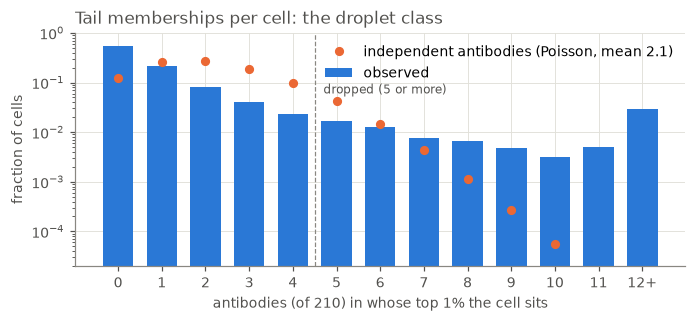

557 of 6508 qc2 cells have five or more tail memberships (8.6%); 241 have ten or more (expected under independence: 0.45)


In [7]:
X210 = P210.loc[qc2.obs_names].to_numpy()
drop, hits = tail_droplets(X210, quantile=0.99, min_hits=5)
n_features = X210.shape[1]
from math import factorial, exp
lam = 0.01 * n_features
poisson = np.array([exp(-lam) * lam ** k / factorial(k) for k in range(12)]); poisson = np.append(poisson, 1 - poisson.sum())
observed = np.bincount(np.minimum(hits, 12), minlength=13) / len(hits)

fig, ax = plt.subplots(figsize=(6.4, 3.0))
k = np.arange(13)
ax.bar(k, observed, width=0.7, color=C['blue'], label='observed')
ax.plot(k, poisson, 'o', ms=5, color=C['orange'], label=f'independent antibodies (Poisson, mean {lam:.1f})')
ax.set_yscale('log'); ax.set_ylim(2e-5, 1)
ax.set_xticks(k); ax.set_xticklabels([str(i) for i in range(12)] + ['12+'])
ax.set_xlabel('antibodies (of 210) in whose top 1% the cell sits'); ax.set_ylabel('fraction of cells')
ax.axvline(4.5, color=C['muted'], lw=0.8, ls='--'); ax.text(4.7, 0.06, 'dropped (5 or more)', color=C['ink'], fontsize=8)
ax.legend(frameon=False, loc='upper right'); ax.set_title('Tail memberships per cell: the droplet class', loc='left', color=C['ink'])
fig.tight_layout(); fig.savefig('figures/dogma_tail_droplets.png'); plt.show()
print(f'{drop.sum()} of {len(drop)} qc2 cells have five or more tail memberships ({100 * drop.mean():.1f}%); '
      f'{(hits >= 10).sum()} have ten or more (expected under independence: {len(hits) * (1 - poisson[:10].sum()):.2f})')

In [8]:
if not os.path.exists(STEM + '_qc3_bg.h5ad'):
    names210 = list(P210.columns); mean = X210.mean(0)
    abund = [j for j in np.argsort(-mean) if mean[j] > 15 and 'sotype' not in names210[j] and 'IgG' not in names210[j]][:25]
    L = np.log1p(X210[:, abund]); fac = np.median(L - L.mean(0), axis=1)
    qc2.obs['adt_tail_hits'] = hits.astype(int); qc2.obs['adt_factor'] = fac
    qc3 = qc2[~drop].copy()
    f = qc3.obs['adt_factor'].to_numpy(); f = f - np.median(f)
    qc3.uns['adt_qc3'] = {'rule': 'drop cells in the top 1% of >= 5 of the 210 antibodies', 'n_dropped': int(drop.sum()), 'n_before': int(qc2.n_obs),
                          'factor_sd_ln': float(f.std()), 'factor': "obs['adt_factor']: median over the 25 abundant antibodies of log1p(count) minus its panel mean"}
    write_h5ad(qc3, STEM + '_qc3_bg.h5ad')
qc3 = ad.read_h5ad(STEM + '_qc3_bg.h5ad')
sigma_cell = float(qc3.uns['adt_qc3']['factor_sd_ln'])
P2, P3 = to_dense(qc2.layers['protein']), to_dense(qc3.layers['protein'])
fano = pd.DataFrame({'mean': P3.mean(0).round(1), 'Fano qc2': (P2.var(0) / P2.mean(0)).round(1), 'Fano qc3': (P3.var(0) / P3.mean(0)).round(1),
                     'max qc2': P2.max(0).astype(int), 'max qc3': P3.max(0).astype(int)}, index=qc3.var_names)
print(f'qc2 {qc2.n_obs} -> qc3 {qc3.n_obs} cells; per-cell factor sd (ln) {sigma_cell:.3f}, a multiplicative spread of x{np.exp(sigma_cell):.2f}')
fano.sort_values('mean', ascending=False).T

qc2 6508 -> qc3 5951 cells; per-cell factor sd (ln) 0.248, a multiplicative spread of x1.28


,CD4,CD27,ITGB7,ITGA4,ICOS,IL2RA,CD52,NOTCH1,FAS,PTPRC,CD226,CD63,CCR10,CXCR6,TNFRSF4,MCAM,TNFSF10,FASLG,CD9,CD79A,NCR3,TNFRSF9,CCR4,CTLA4,LAG3,CCR2,CD68,PDCD1
mean,963.4,74.6,24.7,19.8,18.1,7.3,6.3,5.6,3.9,3.5,2.9,2.5,2.2,2.1,2.0,1.9,1.6,1.5,1.4,1.3,1.2,1.1,1.1,1.1,0.8,0.8,0.6,0.5
Fano qc2,126.5,19.6,54.8,38.0,13.0,29.6,1.8,1.9,4.0,1.7,1.5,14.6,2.7,1.4,2.7,2.0,2.5,1.4,5.3,1.3,1.5,5.6,2.1,1.3,1.2,1.3,1.8,1.7
Fano qc3,82.5,16.1,42.3,31.9,9.5,21.8,1.6,1.6,2.8,1.4,1.4,3.6,1.6,1.3,1.6,1.8,1.5,1.3,4.4,1.2,1.2,2.7,1.6,1.2,1.1,1.1,1.3,1.4
max qc2,4183.0,387.0,624.0,239.0,249.0,282.0,45.0,53.0,56.0,21.0,19.0,164.0,57.0,13.0,42.0,36.0,43.0,21.0,43.0,13.0,28.0,57.0,26.0,8.0,10.0,15.0,21.0,15.0
max qc3,2419.0,387.0,571.0,198.0,244.0,269.0,45.0,30.0,55.0,15.0,19.0,114.0,28.0,12.0,37.0,36.0,31.0,19.0,30.0,8.0,7.0,39.0,17.0,8.0,6.0,7.0,8.0,8.0


The droplet class carried the most extreme counts of several antibodies at once: CD63's Fano
factor falls fourfold, CD137's by half. The abundant antibodies keep Fano factors in the tens,
which is the spread the fits below have to produce.

---
## 4 · The joint fit

`CMEModel("Chromatin", "Poisson", n_sites=2, rule="switch", bursty=True, protein=True)` is the
model; its sampling vector is `[log10 capture (nascent), log10 capture (mature), log10 ATAC dropout,
log10 background factor]`. The ATAC dropout was fixed first by a chromatin-only fit on a dropout
grid (the RNA and the configuration set it, the protein does not); the RNA capture is held at
0.1, the one value every gene accepts (passes 5 and 6 scanned 0.03, 0.1 and 0.3). The protein
background enters per gene from `var` with the grid factor fixed at 1. `protein_limit=50`
coarse-grains the protein axis beyond fifty counts.

Two variants are fitted on the qc3 cells:

- **pass 7a**: the plain model;
- **pass 7b**: the same with `cell_factor=(sigma, 5)`, the measured per-cell factor as a
  unit-mean lognormal scaling every production rate (the transcription rate and the burst size,
  so burst frequency is untouched) and the protein background, integrated by five Gauss–Hermite
  nodes. The generating function is linear in the mixture, so the kernel evaluates the plain
  model once per node; the fit costs about twice as much.

Each pass takes about 45 minutes on a 24-core machine with the adjoint gradient (one backward sweep of
the kernel in place of a 19-point stencil; the saved tables come from the four-hour central-difference
fits; same divergences to three decimals). The cell below runs the passes only on
request and otherwise loads the saved tables.

In [9]:
D_OPT, CAPTURE, PROTEIN_LIMIT = -0.371, -1.0, 50        # log10 dropout from the chromatin-only grid; log10 RNA capture; protein grid cap
GP = {'num_restarts': 1, 'max_iterations': 60, 'init_pattern': 'moments', 'num_gene_cores': 12, 'check_identifiability': True}

def fit_pass(adata, tag, cell_factor=None, start=None, num_cores=12):
    '''The joint fit of every gene of `adata` at the fixed sampling point; writes <tag>.csv and <tag>_results.h5ad under FITS.'''
    model = CMEModel('Chromatin', 'Poisson', n_sites=2, rule='switch', bursty=True, protein=True, protein_limit=PROTEIN_LIMIT,
                     dropout_bounds=(D_OPT, D_OPT, 1), protein_background=(0.0, 0.0, 1), cell_factor=cell_factor)
    # the gradient is the kernel's adjoint (chromatin_grad='auto'): one backward sweep in place of a 19-point stencil
    samp = [CAPTURE, CAPTURE, D_OPT, 0.0]
    gp = dict(GP, num_gene_cores=num_cores)
    if start is not None:                                   # warm start from an earlier results file
        gp['init_pattern'] = 'given'; gp['x0'] = warm_start(start)
    out = perform_inference(adata, model, n_genes=adata.n_vars, viz=False, gradient_params=gp, exclude_sigma=False, num_cores=num_cores,
                            filt_param={'min_means': [0] * 4, 'max_maxes': [100_000] * 4, 'min_maxes': [0] * 4},
                            dataset_string=f'{FITS}/{tag}', seed=1, samp_lb=samp, samp_ub=samp, gridsize=[1, 1, 1, 1])
    sr = search_result_from_uns(out.uns['search_result'])
    sr.chisquare_testing(searchdata_from_adata(out), reject_at_bounds=True)
    names = [p.replace(r'\log_{10} ', '') for p in model.param_str]
    est = pd.DataFrame({n: out.var[n].to_numpy() for n in names}, index=out.var_names)
    for n in names:
        est['error_' + n] = out.var['error_' + n].to_numpy()
    est['error_unreliable'] = out.var['error_unreliable'].to_numpy()
    lb, ub = np.asarray(model.bio_bounds['phys_lb'], float), np.asarray(model.bio_bounds['phys_ub'], float)
    at_bound = ((sr.phys_optimum - lb) < 0.01 * (ub - lb)) | ((ub - sr.phys_optimum) < 0.01 * (ub - lb))
    est['at_bound'] = [','.join(n for n, f in zip(names, row) if f) for row in at_bound]
    est['rejected'] = np.asarray(sr.rejected_genes, bool); est['pval'] = sr.pval; est['hellinger'] = sr.hellinger
    est['hellinger_floor'] = sr.hellinger_floor; est['hellinger_excess'] = sr.hellinger_excess
    klds = np.asarray(sr.klds); est['kld'] = klds[sr.samp_optimum_ind] if klds.ndim == 2 else klds
    out.uns['search_result'] = sr.to_dict()
    est.to_csv(f'{FITS}/{tag}.csv'); write_h5ad(out, f'{FITS}/{tag}_results.h5ad')
    return est

TAG7A = 'mimitou_CD4_T_tss_window_2_protein_qc3_bg_pass7a_joint_cm10'
TAG7B = 'mimitou_CD4_T_tss_window_2_protein_qc3_bg_pass7b_joint_cm10'
if RUN_FITS:
    t0 = time.time(); fit_pass(qc3, TAG7A); print(f'pass 7a: {time.time() - t0:.0f} s')
    r7a = ad.read_h5ad(f'{FITS}/{TAG7A}_results.h5ad')     # pass 7b starts from the pass 7a optimum (the saved tables were fitted cold)
    t0 = time.time(); fit_pass(qc3, TAG7B, cell_factor=(sigma_cell, 5), start=r7a); print(f'pass 7b: {time.time() - t0:.0f} s')
p7a = pd.read_csv(f'{FITS}/{TAG7A}.csv', index_col=0)
p7b = pd.read_csv(f'{FITS}/{TAG7B}.csv', index_col=0)
if 'hellinger_floor' not in p7a.columns:                  # the pass 7a table predates the floor columns; its result object carries them
    sr7a = search_result_from_uns(ad.read_h5ad(f'{FITS}/{TAG7A}_results.h5ad').uns['search_result'])
    p7a['hellinger_floor'] = sr7a.hellinger_floor; p7a['hellinger_excess'] = sr7a.hellinger_excess
NAMES = [c for c in p7a.columns if c.startswith('$')]
print('parameters:', NAMES)
print(f"pass 7a: KLD sum {p7a.kld.sum():.2f}, rejected {int(p7a.rejected.sum())} / {len(p7a)}, at a bound {int((p7a.at_bound.fillna('') != '').sum())}")
print(f"pass 7b: KLD sum {p7b.kld.sum():.2f}, rejected {int(p7b.rejected.sum())} / {len(p7b)}, at a bound {int((p7b.at_bound.fillna('') != '').sum())}")
p7a[NAMES + ['kld', 'hellinger_excess', 'rejected', 'at_bound']].round(3)

parameters: ['$k_{on,0}$', '$k_{on,1}$', '$\\epsilon$', '$a$', '$\\beta$', '$\\gamma$', '$b$', '$k_p$', '$\\gamma_p$']
pass 7a: KLD sum 4.28, rejected 17 / 28, at a bound 13
pass 7b: KLD sum 4.07, rejected 18 / 28, at a bound 14


,"$k_{on,0}$","$k_{on,1}$",$\epsilon$,$a$,$\beta$,$\gamma$,$b$,$k_p$,$\gamma_p$,kld,hellinger_excess,rejected,at_bound
CCR10,-1.127,0.594,-0.325,-3.809,-0.325,-2.278,0.436,-1.718,-2.313,0.078,0.022,False,NaN
CCR2,-1.294,-1.284,-0.281,0.166,0.981,0.097,-0.310,-1.800,1.533,0.012,0.002,True,$k_p$
CCR4,-0.939,-1.133,-0.172,-1.643,-1.033,-1.833,0.396,-1.446,-1.381,0.035,0.008,False,NaN
CD226,-1.107,-0.759,-0.089,0.189,-0.834,-0.378,0.680,-1.419,-1.882,0.050,0.003,False,NaN
CD27,-0.695,-1.298,-0.139,-1.571,-0.145,-2.462,-1.710,-0.712,-2.307,0.214,0.030,True,$\gamma$
CD4,-0.999,-0.868,-0.084,-0.259,-1.090,-0.871,0.123,0.805,-2.208,0.690,0.013,False,NaN
CD52,-1.206,-0.515,-0.166,0.312,0.195,-0.970,0.487,-1.800,-1.920,0.058,0.001,True,$k_p$
CD63,-0.299,-1.118,-0.231,-1.894,-1.426,-2.500,-0.725,-1.800,-2.020,0.320,0.155,True,"$\gamma$,$k_p$"
CD68,-1.142,-0.116,-0.094,-4.000,1.839,-2.292,-3.000,2.341,1.892,0.028,0.008,True,"$a$,$b$"
CD79A,-0.370,-1.016,-0.129,-1.715,0.728,-1.063,0.273,-1.800,1.855,0.018,0.005,True,$k_p$


---
## 5 · Reading a fit against the sampling floor

The goodness-of-fit statistic is a Hellinger distance between the fitted PMF and the observed
histogram over the occupied microstates (`hellinger_statistic`). On a four-dimensional grid
with thousands of distinct states it has a floor: even data drawn from the fitted model does
not reach zero, because every cell occupies its own state. `chisquare_testing` draws multinomial
samples of the data's size from the fitted PMF, scores them with the same statistic and reports
the mean as `hellinger_floor`; the decision uses the **excess** over it. CD4's raw statistic
of 0.28 is almost entirely floor.

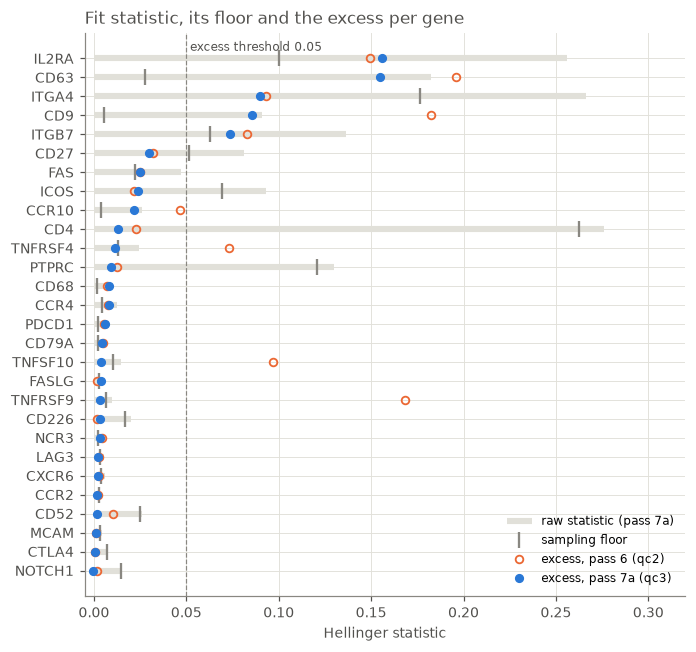

summed excess: {'pass 6 (qc2)': 1.257, 'pass 7a (qc3)': 0.747, 'pass 7b (qc3 + factor)': 0.685}
genes with excess > 0.05: {'pass 6 (qc2)': 8, 'pass 7a (qc3)': 5, 'pass 7b (qc3 + factor)': 5}


,pass 6 (qc2),pass 7a (qc3),pass 7b (qc3 + factor),floor 7a,raw 7a
IL2RA,0.149,0.156,0.158,0.100,0.256
CD63,0.196,0.155,0.154,0.028,0.183
ITGA4,0.093,0.090,0.082,0.177,0.266
CD9,0.182,0.086,0.075,0.005,0.091
ITGB7,0.083,0.074,0.073,0.063,0.136
CD27,0.032,0.030,0.017,0.051,0.081
FAS,0.025,0.025,0.026,0.022,0.047
ICOS,0.022,0.024,0.015,0.069,0.093
CCR10,0.046,0.022,0.015,0.004,0.026
CD4,0.023,0.013,0.013,0.263,0.276


In [10]:
TAG6 = 'mimitou_CD4_T_tss_window_2_protein_qc2_bg_pass6_joint_cm10'
p6 = pd.read_csv(f'{FITS}/{TAG6}.csv', index_col=0)
f6 = pd.read_csv(f'{FITS}/{TAG6}_floor.csv', index_col=0)        # pass 6 (qc2 cells) re-read against the floor
ex = pd.DataFrame({'pass 6 (qc2)': f6.excess, 'pass 7a (qc3)': p7a.hellinger_excess, 'pass 7b (qc3 + factor)': p7b.hellinger_excess,
                   'floor 7a': p7a.hellinger_floor, 'raw 7a': p7a.hellinger}).sort_values('pass 7a (qc3)', ascending=False)
order = ex.index[::-1]
fig, ax = plt.subplots(figsize=(6.4, 6.0))
y = np.arange(len(order))
ax.hlines(y, 0, ex.loc[order, 'raw 7a'], color=C['grid'], lw=4, label='raw statistic (pass 7a)')
ax.plot(ex.loc[order, 'floor 7a'], y, '|', ms=10, mew=1.5, color=C['muted'], label='sampling floor')
ax.plot(ex.loc[order, 'pass 6 (qc2)'], y, 'o', ms=5, mfc='none', mec=C['orange'], mew=1.2, label='excess, pass 6 (qc2)')
ax.plot(ex.loc[order, 'pass 7a (qc3)'], y, 'o', ms=5, color=C['blue'], label='excess, pass 7a (qc3)')
ax.axvline(0.05, color=C['muted'], lw=0.8, ls='--'); ax.text(0.052, len(order) - 0.6, 'excess threshold 0.05', color=C['ink'], fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(order); ax.set_xlabel('Hellinger statistic'); ax.set_xlim(-0.005, 0.32)
ax.legend(frameon=False, loc='lower right', fontsize=8); ax.set_title('Fit statistic, its floor and the excess per gene', loc='left', color=C['ink'])
fig.tight_layout(); fig.savefig('figures/dogma_floor_excess.png'); plt.show()
print('summed excess:', ex[['pass 6 (qc2)', 'pass 7a (qc3)', 'pass 7b (qc3 + factor)']].sum().round(3).to_dict())
print('genes with excess > 0.05:', (ex[['pass 6 (qc2)', 'pass 7a (qc3)', 'pass 7b (qc3 + factor)']] > 0.05).sum().to_dict())
ex.round(3)

Three things to read off the figure and the table.

- **Most of the raw statistic of the abundant antibodies is floor.** CD4, CD45, CD49d sit at
  0.13 to 0.28 raw; their excess is 0.01 to 0.09.
- **qc3 removed the tails of CD137, TNFSF10 and OX40** (excess 0.17, 0.10, 0.07 down to under
  0.012): their heavy tails were the droplet class. CD9 halved. CD25, CD63, CD49d and integrin β7
  did not move: those tails are cells.
- **The per-cell factor barely changes the fit** (summed excess 0.75 to 0.69) but moves the
  estimates where it absorbs overdispersion, as the next cell shows.

In [11]:
shift = (p7b[NAMES] - p7a[NAMES])
summary = pd.DataFrame({'median |shift| (log10)': shift.abs().median().round(3)}).T
print('pass 7b minus pass 7a, over the 28 genes:'); display(summary)
show = ['CD4', 'CD27', 'ICOS', 'IL2RA', 'ITGA4', 'CXCR6', 'PTPRC']
tab = pd.concat({'7a': p7a.loc[show, NAMES[3:]], 'shift 7b-7a': shift.loc[show, NAMES[3:]]}, axis=1).round(2)
print('well-identified genes shift a little (CD4: smaller burst size, k_p and gamma_p); valley genes (CXCR6, CD45) swing along their flat direction:')
tab

pass 7b minus pass 7a, over the 28 genes:


,"$k_{on,0}$","$k_{on,1}$",$\epsilon$,$a$,$\beta$,$\gamma$,$b$,$k_p$,$\gamma_p$
median |shift| (log10),0.008,0.006,0.007,0.07,0.067,0.076,0.052,0.129,0.191


well-identified genes shift a little (CD4: smaller burst size, k_p and gamma_p); valley genes (CXCR6, CD45) swing along their flat direction:


7a                                         shift 7b-7a                                        
        $a$ $\beta$ $\gamma$   $b$ $k_p$ $\gamma_p$         $a$ $\beta$ $\gamma$   $b$ $k_p$ $\gamma_p$
CD4   -0.26   -1.09    -0.87  0.12  0.81      -2.21       -0.02   -0.01    -0.02 -0.32 -0.40      -0.41
CD27  -1.57   -0.14    -2.46 -1.71 -0.71      -2.31       -0.15    0.03    -0.04  1.23 -0.58      -0.69
ICOS  -0.93   -2.06    -1.30  0.47 -0.65      -1.81        0.38    0.39     0.39  0.02  0.17       0.14
IL2RA  1.72    0.52     1.12  1.28 -0.20      -0.99       -0.04   -0.04    -0.03 -0.05  0.02      -0.01
ITGA4  0.89   -0.51     0.23  1.40  0.19      -0.81       -0.07   -0.05    -0.05 -0.03 -0.07      -0.07
CXCR6 -0.75    2.47    -0.76 -2.94  1.43       1.16        0.04    0.03     0.12  3.28 -2.50      -2.55
PTPRC  1.59   -0.78    -0.58 -0.28 -1.80      -0.90       -0.03    0.00     0.00 -2.46  0.00      -0.00

The factor is a correction to the estimates of the broad antibodies, not a fix for their fit:
CD4's burst size, `k_p` and `gamma_p` each fall by 0.3 to 0.4 log10 when the overdispersion
has somewhere else to go, while CXCR6 and CD45, whose likelihood is flat along the trade-off
between burst size and protein production, jump by two or three log10 at no change in fit.

---
## 6 · The heavy tails

What keeps CD25, CD63, CD49d, integrin β7 and CD9 rejected? The protein marginal of the fit
against the data answers it: a thin-tailed protein layer fitted by maximum likelihood chases
the tail and puts 6 to 22% of its mass above the observed 99th percentile (1% by construction),
so its mean lands well above the observed mean while the bulk of the distribution is missed.
The RNA marginals fit. Grid resolution is not the cause (the statistic binned to the coarse
protein axis equals the full one).

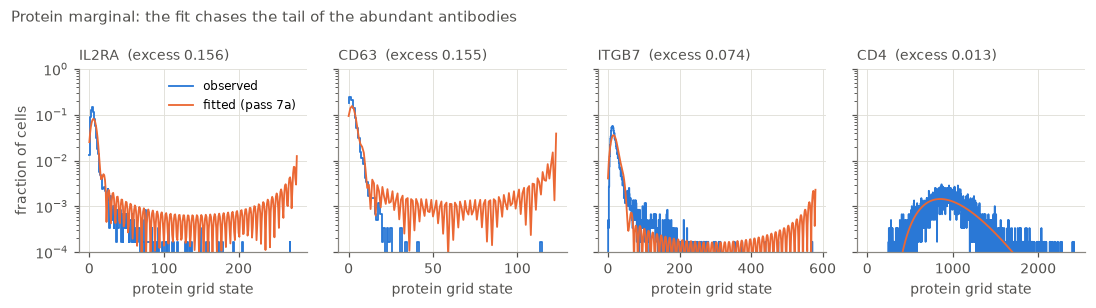

,excess,mean obs,mean fit,q99 obs,mass above q99: obs,fit
gene,,,,,,
IL2RA,0.156,7.331,46.074,64,0.010,0.185
CD63,0.155,2.454,21.583,12,0.010,0.221
ITGB7,0.074,24.737,60.750,176,0.010,0.089
CD4,0.013,963.410,967.834,1872,0.010,0.007
CD9,0.086,1.422,2.036,13,0.008,0.007
ITGA4,0.090,19.831,31.380,121,0.009,0.062
CD27,0.030,74.609,75.558,183,0.010,0.010
TNFRSF9,0.003,1.074,1.034,6,0.009,0.011


In [12]:
res7a = ad.read_h5ad(f'{FITS}/{TAG7A}_results.h5ad')
sr7a = search_result_from_uns(res7a.uns['search_result']); sd7a = searchdata_from_adata(res7a); names7a = list(res7a.var_names)
def protein_marginals(gene):
    i = names7a.index(gene); M = np.array(sd7a.M[:, i]); idx = np.asarray(sd7a.hist[i][0]); fr = np.asarray(sd7a.hist[i][1])
    obs = np.zeros(int(M[2])); np.add.at(obs, idx[:, 2], fr)
    fit = np.asarray(sr7a.gene_pss(sd7a, i)); fit = fit / fit.sum(); fit = fit.sum(axis=(0, 1, 3))
    return obs, fit
rows = []; panels = ['IL2RA', 'CD63', 'ITGB7', 'CD4']
marg = {}
for g in panels + ['CD9', 'ITGA4', 'CD27', 'TNFRSF9']:
    obs, fit = protein_marginals(g); x = np.arange(len(obs)); marg[g] = (obs, fit)
    q99 = x[np.searchsorted(np.cumsum(obs), 0.99)]
    rows.append({'gene': g, 'excess': p7a.loc[g, 'hellinger_excess'], 'mean obs': (obs * x).sum(), 'mean fit': (fit * x).sum(),
                 'q99 obs': int(q99), 'mass above q99: obs': obs[x > q99].sum(), 'fit': fit[x > q99].sum()})
tails = pd.DataFrame(rows).set_index('gene')
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8), sharey=True)
for axx, g in zip(axes, panels):
    obs, fit = marg[g]; x = np.arange(len(obs)); keep = obs > 0
    axx.step(x, np.maximum(obs, 1e-6), where='mid', color=C['blue'], lw=1.2, label='observed')
    axx.plot(x, fit, color=C['orange'], lw=1.2, label='fitted (pass 7a)')
    axx.set_yscale('log'); axx.set_ylim(1e-4, 1); axx.set_title(f"{g}  (excess {p7a.loc[g, 'hellinger_excess']:.3f})", loc='left', fontsize=9, color=C['ink'])
    axx.set_xlabel('protein grid state')
axes[0].set_ylabel('fraction of cells'); axes[0].legend(frameon=False, fontsize=8, loc='upper right')
fig.suptitle('Protein marginal: the fit chases the tail of the abundant antibodies', x=0.01, ha='left', color=C['ink'], fontsize=10)
fig.tight_layout(); fig.savefig('figures/dogma_protein_tails.png'); plt.show()
tails.round(3)

(The protein axis is the model's grid: fifty states up to `protein_limit`, then coarse bins.)
CD4 fits, with its mean reproduced; CD25, CD63 and integrin β7 are fitted with means 2.5 to 9
times the observed and tails far heavier than the data. The tail cells are not shared across
these antibodies (chance-level overlap), so they are not a second droplet class: each is a
property of its own antibody, or of a cell state.

---
## 7 · Cell state: activated and resting CD4 T cells

CD25, CD137 and OX40 are activation markers, and the GEX clusters 2 and 8 of the assembly hold
their tails (14% and 10% of those cells above four times the CD25 median, against under 1% in
the resting clusters). The five genes CD25, CD137, OX40, CD4 and CD27 were fitted separately
on the activated clusters (2, 8) and on the resting clusters (0, 9, 10, 11).

A detail that matters for any fit on a few thousand cells: the cold resting-stratum fit of CD25
landed at a divergence of 1.32 where the pooled optimum gave 0.35, a start problem. Refitted
from the pooled optimum (`gradient_params={"init_pattern": "given", "x0": warm_start(results)}`)
it reached 0.31. The table shows the warm-started value.

In [13]:
cl = qc3.obs['cluster'].astype(int).values
act_genes = ['IL2RA', 'TNFRSF9', 'TNFRSF4']
Pq = pd.DataFrame(P3[:, [list(qc3.var_names).index(g) for g in act_genes]], columns=act_genes, index=qc3.obs_names)
frac_hi = pd.DataFrame({g: (Pq[g] > 4 * max(np.median(Pq[g]), 1)).groupby(cl).mean() * 100 for g in act_genes})
frac_hi['cells'] = pd.Series(cl).value_counts().sort_index().values
print('percent of cells above 4x the median, by GEX cluster:'); display(frac_hi.round(1).T)

STRATA = {'activated (2, 8)': ('act5', np.isin(cl, [2, 8])), 'resting (0, 9, 10, 11)': ('rest5', np.isin(cl, [0, 9, 10, 11]))}
genes5 = ['IL2RA', 'TNFRSF9', 'TNFRSF4', 'CD4', 'CD27']
strata = {}
for label, (suffix, keep) in STRATA.items():
    tag = f'mimitou_CD4_T_tss_window_2_protein_qc3_bg_{suffix}_fit7c_joint_cm10'
    if RUN_FITS and not os.path.exists(f'{FITS}/{tag}.csv'):
        sub = qc3[keep, genes5].copy(); write_h5ad(sub, f'{STEM}_qc3_bg_{suffix}.h5ad')
        fit_pass(sub, tag, start=f'{FITS}/{TAG7A}_results.h5ad')     # warm start from the pooled optimum
    strata[label] = pd.read_csv(f'{FITS}/{tag}.csv', index_col=0)
warm = f'{FITS}/mimitou_CD4_T_tss_window_2_protein_qc3_bg_rest5_fit7c_warm_IL2RA_joint_cm10.csv'
if os.path.exists(warm):                                               # the warm-started CD25 refit replaces the cold one
    w = pd.read_csv(warm, index_col=0)
    for c in w.columns:
        if c in strata['resting (0, 9, 10, 11)'].columns:
            strata['resting (0, 9, 10, 11)'].loc['IL2RA', c] = w.loc['IL2RA', c]
cols = ['$a$', '$b$', '$k_p$', '$\\gamma_p$', 'kld', 'hellinger_floor', 'hellinger_excess', 'rejected']
comp = pd.concat({'pooled (pass 7a)': p7a.loc[genes5, cols], **{k: v.loc[genes5, cols] for k, v in strata.items()}}, axis=0)
comp.swaplevel().sort_index(level=0, sort_remaining=False).round(3)

percent of cells above 4x the median, by GEX cluster:


,0,2,7,8,9,10,11
IL2RA,4.7,13.8,0.0,10.2,2.1,4.1,0.9
TNFRSF9,0.7,10.5,0.0,4.5,0.9,1.6,0.5
TNFRSF4,0.1,4.0,0.0,0.5,0.2,0.7,0.0
cells,812.0,275.0,3.0,935.0,1169.0,614.0,2143.0


$a$    $b$  $k_p$  $\gamma_p$    kld  hellinger_floor  hellinger_excess  rejected
CD27    pooled (pass 7a)       -1.571 -1.710 -0.712      -2.307  0.214            0.051             0.030      True
        activated (2, 8)        0.042 -2.969  1.157      -0.409  0.525            0.161             0.037      True
        resting (0, 9, 10, 11) -1.616 -0.117 -1.249      -2.998  0.181            0.053             0.014      True
CD4     pooled (pass 7a)       -0.259  0.123  0.805      -2.208  0.690            0.263             0.013     False
        activated (2, 8)       -0.832  0.123  0.096      -2.774  1.572            0.622            -0.008     False
        resting (0, 9, 10, 11) -0.069  0.051  1.047      -2.015  0.747            0.279             0.015     False
IL2RA   pooled (pass 7a)        1.719  1.285 -0.201      -0.989  0.586            0.100             0.156      True
        activated (2, 8)        1.871  1.331 -0.212      -0.653  1.199            0.311             0.080      True
        resting (0, 9, 10, 11)  1.462  1.110 -0.196      -1.171  0.314            0.056             0.076      True
TNFRSF4 pooled (pass 7a)       -1.760  1.274 -1.794      -0.803  0.080            0.013             0.011      True
        activated (2, 8)       -1.465  1.266 -1.800      -0.763  0.251            0.070             0.012      True
        resting (0, 9, 10, 11) -2.437  0.526 -1.800      -1.337  0.043            0.007             0.007      True
TNFRSF9 pooled (pass 7a)       -0.950  0.895 -1.519      -1.896  0.030            0.007             0.003     False
        activated (2, 8)       -0.560  0.991 -1.138      -1.430  0.109            0.033             0.006     False
        resting (0, 9, 10, 11) -1.159  0.468 -1.739      -2.344  0.008            0.003            -0.000     False

CD137 and OX40 fit in both strata and differ in the expected way: the activated cells have a
transcription rate four to ten times and a burst size three to five times the resting cells'.
CD25 is not rescued: both strata are rejected (excess 0.08 in each, against 0.16 pooled), so its
tail lies within the states, not between them. The controls show the limit of a 1,210-cell
stratum: CD4 and CD27 find other points on their flat directions at the same excess.

The decision recorded in the design doc: no bespoke model for these five antibodies' tails.
Their RNA parameters are reported from a chromatin-plus-RNA fit and their protein parameters
withheld.

---
## 8 · The burst-size check

Dropping the protein layer gives the reference the previous section needs. The RNA-only fit
pins the burst size with the nascent and mature counts alone, with standard errors of a few
hundredths for an abundant gene. `inference.rna_only_check` rebuilds the fitted model without
its protein layer, refits every gene on the same cells at the joint capture and dropout, and
reports the joint-minus-RNA shift of each shared parameter in units of the RNA-only error.

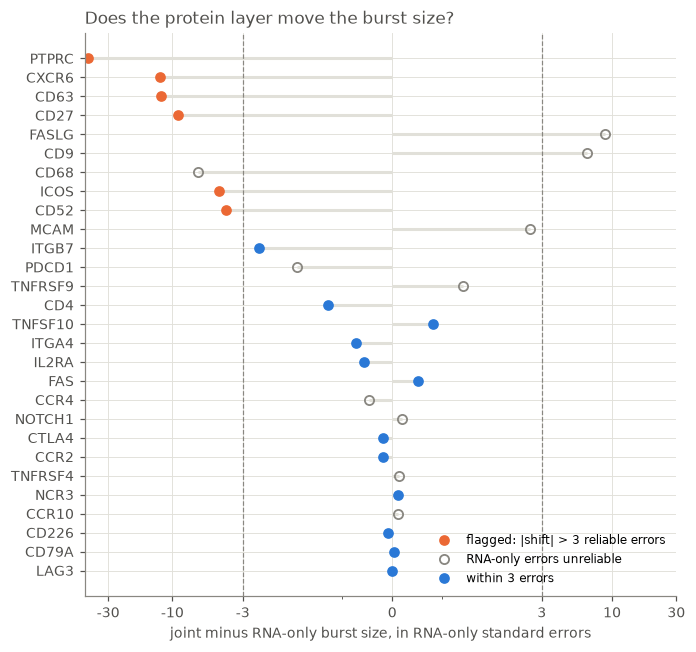

flagged: 6 of 28 genes; RNA-only fit rejected on 3


,rna_only_$b$,rna_only_error_$b$,shift_$b$,b_shift_sigma,protein_biases_b,rna_only_error_unreliable,rna_only_hellinger_excess,joint excess
PTPRC,1.169,0.034,-1.448,-42.312,True,False,0.001,0.009
CXCR6,0.366,0.266,-3.308,-12.423,True,False,-0.000,0.002
CD63,0.399,0.093,-1.125,-12.121,True,False,-0.001,0.155
CD27,-0.060,0.181,-1.650,-9.128,True,False,-0.000,0.030
FASLG,-1.642,0.146,1.298,8.889,False,True,-0.000,0.004
CD9,-1.392,0.146,0.954,6.534,False,True,-0.000,0.086
CD68,-2.063,0.146,-0.937,-6.415,False,True,-0.000,0.008
ICOS,0.656,0.042,-0.189,-4.537,True,False,-0.000,0.024
CD52,0.637,0.038,-0.150,-3.969,True,False,0.000,0.001
MCAM,0.346,0.146,0.405,2.772,False,True,-0.000,0.001


In [14]:
check_csv = f'{FITS}/{TAG7A}_rna_check.csv'
if RUN_FITS or not os.path.exists(check_csv):
    t0 = time.time()
    check = rna_only_check(res7a, gradient_params=dict(GP, check_identifiability=False), num_cores=12)
    check.to_csv(check_csv); print(f'{time.time() - t0:.0f} s')
check = pd.read_csv(check_csv, index_col=0)
order = check['b_shift_sigma'].abs().sort_values().index
y = np.arange(len(order)); z = check.loc[order, 'b_shift_sigma']
flag = check.loc[order, 'protein_biases_b'].astype(bool); unrel = check.loc[order, 'rna_only_error_unreliable'].astype(bool)
fig, ax = plt.subplots(figsize=(6.4, 6.0))
ax.hlines(y, 0, z, color=C['grid'], lw=2)
ax.plot(z[flag], y[flag.values], 'o', ms=6, color=C['orange'], label='flagged: |shift| > 3 reliable errors')
ax.plot(z[unrel], y[unrel.values], 'o', ms=6, mfc='none', mec=C['muted'], mew=1.2, label='RNA-only errors unreliable')
rest = ~flag & ~unrel
ax.plot(z[rest], y[rest.values], 'o', ms=6, color=C['blue'], label='within 3 errors')
for v in (-3, 3):
    ax.axvline(v, color=C['muted'], lw=0.8, ls='--')
ax.set_xscale('symlog', linthresh=3); ax.set_xticks([-30, -10, -3, 0, 3, 10, 30]); ax.set_xticklabels(['-30', '-10', '-3', '0', '3', '10', '30'])
ax.set_yticks(y); ax.set_yticklabels(order); ax.set_xlabel('joint minus RNA-only burst size, in RNA-only standard errors')
ax.legend(frameon=False, loc='lower right', fontsize=8); ax.set_title('Does the protein layer move the burst size?', loc='left', color=C['ink'])
fig.tight_layout(); fig.savefig('figures/dogma_b_shift.png'); plt.show()
out_cols = ['rna_only_$b$', 'rna_only_error_$b$', 'shift_$b$', 'b_shift_sigma', 'protein_biases_b', 'rna_only_error_unreliable', 'rna_only_hellinger_excess']
show = check.loc[order[::-1], out_cols].copy(); show['joint excess'] = p7a.loc[show.index, 'hellinger_excess']
print(f"flagged: {int(check.protein_biases_b.sum())} of {len(check)} genes; RNA-only fit rejected on {int(check.rna_only_rejected.sum())}")
show.head(12).round(3)

Every gene fits without the protein layer (excess at most 0.003). The shifts fall in three
groups. CD25 and CD49d, whose RNA is abundant, do not move: the RNA pins `b` and the protein
tail cannot pull it. CD63, integrin β7, CD9 and the rejected set move by half a decade to a
decade. And **CD45 and CD27 move by 1.4 to 1.7 log10 although their protein layer passes** the
fit test (excess 0.009 and 0.03): a passing protein fit does not guarantee an unbiased burst
size. Hence the rule the pipeline now follows.

---
## 9 · What the dataset taught

1. **Report the excess over the sampling floor, not the raw statistic.** On a four-dimensional
   grid the raw statistic of an abundant gene is mostly floor.
2. **Two quality-control steps belong before any protein fit**: aggregate-carrying cells
   (any antibody above three times its 99th percentile) and the multi-antibody droplet class
   (`tail_droplets`). The second removed the heavy tails of three of the eight rejected genes.
3. **The per-antibody background is a fixed per-gene rate**, measured on a negative cell type.
   A rate shared across antibodies has the wrong shape.
4. **The measured per-cell factor** (`cell_factor`) corrects the estimates of the broad
   antibodies, CD4 most of all, at twice the cost; it does not fix their fit.
5. **Five abundant antibodies have protein tails inside the cell states** that a single
   production rate cannot carry. Their RNA parameters come from the RNA-only fit; their protein
   parameters are withheld.
6. **Run `rna_only_check` after every joint fit.** The protein layer can move the burst size by
   an order of magnitude in a gene whose protein fit passes.
7. **Warm-start subset fits** from a pooled optimum (`warm_start`); a cold start on a few
   thousand cells can settle in a poor optimum.

The design record with every pass and its numbers is `docs/chromatin-protein-design.md`.